# Tasa de esfuerzo de los hogares que pagan alquiler

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"  # carpeta en research/temas/
GRAFICA_ID = "esfuerzo-alquiler"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Tasa de esfuerzo de los hogares que pagan alquiler"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de la renta disponible del hogar"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Qué parte de su renta disponible dedican al alquiler de la vivienda principal los hogares que pagan alquiler, según la encuesta europea de condiciones de vida (EU-SILC; en España, la Encuesta de Condiciones de Vida del INE).

**Cómo se lee.** Un valor de 27 significa que el alquiler se lleva el 27 % de la renta disponible del hogar inquilino.

**Limitaciones.**
- Solo cuenta el alquiler, no el resto de gastos de la vivienda (suministros, comunidad).
- Recoge a todos los hogares inquilinos, también a los que pagan un alquiler reducido.
- EE. UU. y Canadá: la OCDE publica la **mediana** de esta proporción, que en España da valores distintos de los de Eurostat; al no ser comparables, esas series quedan sin dato (ver la comparación en la transformación). La OCDE no publica una media de sus países.

## 2. Descarga

- **España y UE-27:** Eurostat `ilc_mded02` (todos los hogares, sin desglose por renta, %).
- **Comparación:** OECD Affordable Housing Database, HC1.2 (hoja `HC12_A1`, «Rent (private and subsidized)», proporción × 100), para comprobar si EE. UU. y Canadá son comparables.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from datetime import date

from lib import eurostat, oecd, oecd_ahd
from lib.tipos import FuenteMeta


def descargar():
    euro, f_euro = eurostat.get("ilc_mded02", {"freq": "A", "hhcomp": "TOTAL", "rskpovth": "TOTAL", "unit": "PC"}, desde=DESDE)
    ahd, _ = oecd_ahd.get("HC1-2-Housing-costs-over-income", "HC12_A1", categoria="Rent (private and subsidized)",
                          paises={"Spain": "espana", "United States": "eeuu", "Canada": "canada"}, escala=100, desde=DESDE)
    return euro, f_euro, ahd


euro, f_euro, ahd = descargar()

## 3. Transformación

Se compara en España la cifra de Eurostat con la de la OCDE. Si no coinciden, EE. UU. y Canadá (que solo están en la OCDE) se dejan sin dato, como pide el config, en lugar de mezclar dos estadísticas distintas.

In [ ]:
def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    hoy = date.today().isoformat()
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, hoy) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]

# ¿Es comparable la OCDE con Eurostat? Se mira en España, que está en las dos fuentes
comun = euro[euro.serie == "espana"].merge(ahd[ahd.serie == "espana"], on="periodo", suffixes=("_eurostat", "_ocde"))
DIF = (comun["valor_ocde"] - comun["valor_eurostat"]).abs().mean()
print(comun.round(1).to_string(index=False))
print(f"Diferencia media en España (alquiler sobre renta): {DIF:.1f} puntos")

df, fuentes = euro, f_euro
AHD = ("OECD", "Affordable Housing Database, HC1-2-Housing-costs-over-income (HC12_A1, consultada, no usada)", "https://webfs.oecd.org/els-com/Affordable_Housing_Database/HC1-2-Housing-costs-over-income.xlsx")
df, fuentes = anadir_sin_dato(df, fuentes, {"ocde": AHD, "eeuu": AHD, "canada": AHD})

NOTAS = [
    "España y UE-27: Eurostat ilc_mded02, proporción de la renta disponible del hogar destinada al alquiler de la vivienda principal (EU-SILC; en España, Encuesta de Condiciones de Vida del INE). UE-27 de composición actual (EU27_2020).",
    f"EE. UU. y Canadá: la OECD Affordable Housing Database (HC1.2) publica la mediana de esta proporción; en España difiere de la cifra de Eurostat en {DIF:.1f} puntos de media en los años comunes, así que no es comparable y esas series quedan sin dato.",
    "OCDE: la OECD Affordable Housing Database no publica una media de sus países en las series anuales.",
]

serie_eurostat  periodo  valor_eurostat serie_ocde  valor_ocde
        espana     2010            32.1     espana        26.3
        espana     2011            31.2     espana        26.2
        espana     2012            31.6     espana        25.4
        espana     2013            31.6     espana        25.6
        espana     2014            33.0     espana        26.3
        espana     2015            32.1     espana        25.0
        espana     2016            32.2     espana        24.9
        espana     2017            32.1     espana        26.5
        espana     2018            29.8     espana        24.5
        espana     2019            32.1     espana        25.6
        espana     2020            29.9     espana        25.1
        espana     2021            33.1     espana        26.0
        espana     2022            30.7     espana        25.8
        espana     2023            26.9     espana        23.9
        espana     2024            26.7     espana     

## 4. Visualización

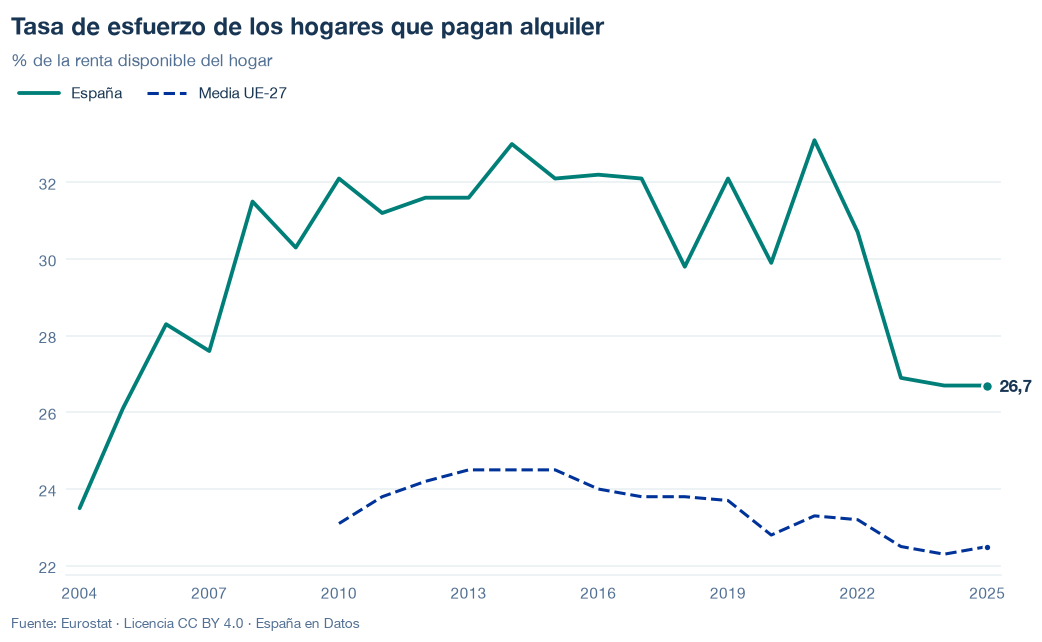

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/esfuerzo-alquiler.json y data/esfuerzo-alquiler.csv


## 6. Fuentes, notas y licencia

- Eurostat, `ilc_mded02`.
- OECD Affordable Housing Database, HC1.2 (`HC12_A1`), solo para la comparación.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.